# HiMAE PVC Detection

This notebook runs the released **HiMAE** backbone end to end on the synthetic PVC example:

1. builds HiMAE with the architecture reported in the main text (`PAPER_CONFIG`) and loads `himae_synth.ckpt`;
2. resamples the stored windows to the pretraining input format (100 Hz, 10 s = 1,000 samples, min-max normalized);
3. splits participants into disjoint train / validation / test sets;
4. trains a linear probe on the mean-pooled bottleneck (stage 5) and exports predictions to `results/` (the released `pvc_linear_probe.pt` / `pvc_predictions.csv` are left unchanged);
5. probes **every encoder stage** (one embedding per temporal resolution) to test the resolution hypothesis.

| Setting | Main text | Code |
|---|---|---|
| Input | 10 s at 100 Hz (1,000 samples) | `PAPER_CONFIG["sampling_freq"]`, `PAPER_CONFIG["seg_len"]` |
| Channel hierarchy | [16, 32, 64, 128, 256] | `PAPER_CONFIG["channels"]` |
| Kernel / stride | 5 / 2 | `PAPER_CONFIG["kernel_size"]`, `PAPER_CONFIG["stride"]` |
| Patch size / mask ratio | 5 / 0.8 | `PAPER_CONFIG["patch_len"]`, `PAPER_CONFIG["mask_ratio"]` |

In [1]:
# Optional: install dependencies if your environment doesn't have them
# %pip install torch numpy pandas scikit-learn scipy matplotlib h5py

In [2]:
import os, sys, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [3]:
# Repo import path: the 'pvc' package root where utils/ and downstream_eval/ live.
REPO_DIR = os.path.abspath("./pvc")
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from utils.model_arch.himae import HiMAE, PAPER_CONFIG
from utils.signal_utils import load_h5_windows, participant_disjoint_split
print("PAPER_CONFIG:", PAPER_CONFIG)

PAPER_CONFIG: {'sampling_freq': 100, 'seg_len': 10, 'channels': (16, 32, 64, 128, 256), 'kernel_size': 5, 'stride': 2, 'patch_len': 5, 'mask_ratio': 0.8}


In [4]:
# Paths & configuration
H5_PATH    = "./pvc_10s_synth.h5"   # windows stored at 25 Hz (250 samples); resampled to 100 Hz below
SIGNAL_KEY = "ppg"
LABEL_KEY  = "labels"
PID_KEY    = "patient_ids"
INPUT_FS   = None                   # inferred from window length (250 samples / 10 s = 25 Hz)

CFG = dict(
    source=SIGNAL_KEY,
    sampling_freq=PAPER_CONFIG["sampling_freq"],   # 100 Hz model input
    seg_len=PAPER_CONFIG["seg_len"],               # 10 s
    model_params=dict(
        channels=PAPER_CONFIG["channels"],
        kernel_size=PAPER_CONFIG["kernel_size"],
        stride=PAPER_CONFIG["stride"],
        patch_len=PAPER_CONFIG["patch_len"],
    ),
)

BACKBONE_CKPT = "./himae_synth.ckpt"
SEED = 7
SPLIT_SEED = 77            # same participant split as fewshot_finetune.py / multiresolution_probe.py
TEST_FRACTION, VAL_FRACTION = 0.20, 0.20
BATCH_SIZE = 512
OUT_DIR = "./results"      # outputs go here; the released pvc_linear_probe.pt / pvc_predictions.csv are not overwritten
os.makedirs(OUT_DIR, exist_ok=True)

In [5]:
# Build the HiMAE backbone and load the pretrained weights
torch.manual_seed(SEED)
np.random.seed(SEED)
backbone = HiMAE(CFG)

state = torch.load(BACKBONE_CKPT, map_location="cpu", weights_only=False)
sd = state.get("state_dict", state)
sd = {k[len("model."):] if k.startswith("model.") else k: v for k, v in sd.items()}
missing, unexpected = backbone.load_state_dict(sd, strict=False)
print("Missing keys:", len(missing), "| Unexpected keys:", len(unexpected))
print("Checkpoint hyper-parameters:", {k: state["hyper_parameters"][k] for k in ("f_s", "T", "patch", "channels", "mask_ratio")})
print(f"Parameters: {sum(p.numel() for p in backbone.parameters()):,}")
backbone = backbone.to(device).eval()

geometry = pd.DataFrame(backbone.stage_geometry())
geometry["receptive_field_ms"] = 1000 * geometry["receptive_field"] / CFG["sampling_freq"]
geometry["time_step_ms"] = 1000 * geometry["downsample"] / CFG["sampling_freq"]
geometry

Missing keys: 0 | Unexpected keys: 0
Checkpoint hyper-parameters: {'f_s': 100, 'T': 10, 'patch': 5, 'channels': [16, 32, 64, 128, 256], 'mask_ratio': 0.8}
Parameters: 1,245,953


,stage,channels,downsample,length,receptive_field,receptive_field_ms,time_step_ms
0,1,16,2,500,13,130.0,20.0
1,2,32,4,250,37,370.0,40.0
2,3,64,8,125,85,850.0,80.0
3,4,128,16,63,181,1810.0,160.0
4,5,256,32,32,373,3730.0,320.0


In [6]:
# Load windows (resampled to 100 Hz, min-max normalized) and split by participant
x, y, pid = load_h5_windows(H5_PATH, SIGNAL_KEY, LABEL_KEY, PID_KEY, input_fs=INPUT_FS,
                            model_fs=CFG["sampling_freq"], seg_len=CFG["seg_len"])
tr, va, te = participant_disjoint_split(y, pid, TEST_FRACTION, VAL_FRACTION, SPLIT_SEED)
print(f"windows={len(y):,}  length={x.shape[1]} samples  prevalence={y.mean():.3f}")
for name, idx in (("train", tr), ("val", va), ("test", te)):
    print(f"{name:>5}: {len(idx):6,d} windows, {len(np.unique(pid[idx])):2d} participants, {int(y[idx].sum()):5,d} PVC")

windows=55,861  length=1000 samples  prevalence=0.047
train: 35,185 windows, 11 participants, 1,278 PVC
  val:  9,467 windows,  3 participants, 1,129 PVC
 test: 11,209 windows,  4 participants,   197 PVC


In [7]:
# Frozen encoder: one time-pooled embedding per encoder stage (multi-resolution embeddings)
@torch.no_grad()
def extract_multiresolution(backbone, x, pooling="mean", batch_size=BATCH_SIZE):
    chunks = [[] for _ in backbone.encoder_layers]
    for i in range(0, len(x), batch_size):
        xb = torch.from_numpy(x[i:i + batch_size]).unsqueeze(1).to(device)
        for k, e in enumerate(backbone.embed_multiresolution(xb, pooling=pooling)):
            chunks[k].append(e.cpu().numpy())
    return [np.concatenate(c) for c in chunks]

stage_feats = extract_multiresolution(backbone, x)
for k, f in enumerate(stage_feats, start=1):
    print(f"stage {k}: embedding dim {f.shape[1]}")

stage 1: embedding dim 16
stage 2: embedding dim 32
stage 3: embedding dim 64
stage 4: embedding dim 128
stage 5: embedding dim 256


## Linear probe on the bottleneck (stage 5)

The standard frozen evaluation: global average pooling of the final encoder stage followed by a linear layer.
The probe is selected on the validation split and evaluated once on the held-out test participants.

In [8]:
class LinearProbe(nn.Module):
    def __init__(self, in_dim=256, num_classes=1):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)

    def forward(self, feats):
        if feats.dim() == 3:          # (B, C, T') feature map -> global average pooling
            feats = feats.mean(dim=-1)
        return self.fc(feats).squeeze(-1)

def train_linear_probe(z, epochs=30, lr=1e-3, weight_decay=1e-4, batch_size=1024):
    torch.manual_seed(SEED)
    mu, sd = z[tr].mean(0), z[tr].std(0) + 1e-6   # standardize with training statistics
    zt = torch.from_numpy((z - mu) / sd).float()
    probe = LinearProbe(z.shape[1]).to(device)
    opt = torch.optim.AdamW(probe.parameters(), lr=lr, weight_decay=weight_decay)
    yt = torch.from_numpy(y).float()
    best, best_state = -np.inf, None
    for ep in range(1, epochs + 1):
        probe.train()
        for b in np.array_split(np.random.permutation(tr), max(1, len(tr) // batch_size)):
            loss = nn.functional.binary_cross_entropy_with_logits(probe(zt[b].to(device)), yt[b].to(device))
            opt.zero_grad(); loss.backward(); opt.step()
        probe.eval()
        with torch.no_grad():
            val_auc = roc_auc_score(y[va], torch.sigmoid(probe(zt[va].to(device))).cpu().numpy())
        if val_auc > best:
            best, best_state = val_auc, {k: v.detach().cpu().clone() for k, v in probe.state_dict().items()}
    probe.load_state_dict(best_state)
    # Fold the standardization into the linear layer so the saved probe acts on raw pooled embeddings
    with torch.no_grad():
        w = probe.fc.weight / torch.from_numpy(sd).float().to(device)
        probe.fc.bias -= (w * torch.from_numpy(mu).float().to(device)).sum(1)
        probe.fc.weight.copy_(w)
    return probe, best

probe, best_val_auc = train_linear_probe(stage_feats[-1])
print(f"Best validation AUROC: {best_val_auc:.4f}")
torch.save({k: v.cpu() for k, v in probe.state_dict().items()}, os.path.join(OUT_DIR, "pvc_linear_probe.pt"))
print("Saved probe to", os.path.join(OUT_DIR, "pvc_linear_probe.pt"))

Best validation AUROC: 0.9025
Saved probe to ./results/pvc_linear_probe.pt


In [9]:
# Held-out test evaluation and prediction export (validation + test rows, labelled by split)
with torch.no_grad():
    scores = torch.sigmoid(probe(torch.from_numpy(stage_feats[-1]).float().to(device))).cpu().numpy()
print(f"Test AUROC: {roc_auc_score(y[te], scores[te]):.4f} | Test AP: {average_precision_score(y[te], scores[te]):.4f}")

sample_id = pd.Series(np.arange(len(y))).groupby(pid).cumcount().to_numpy()
rows = np.concatenate([va, te])
pred = pd.DataFrame({
    "patient_id": pid[rows], "sample_id": sample_id[rows],
    "split": np.where(np.isin(rows, te), "test", "val"),
    "label": y[rows], "p_pvc": scores[rows],
})
pred.to_csv(os.path.join(OUT_DIR, "pvc_predictions.csv"), index=False)
print(f"Wrote {os.path.join(OUT_DIR, 'pvc_predictions.csv')} ({len(pred):,} rows)")

Test AUROC: 0.9093 | Test AP: 0.3896
Wrote ./results/pvc_predictions.csv (20,676 rows)


## Multi-resolution embeddings (resolution hypothesis)

Each encoder stage halves the temporal resolution, so stage *k* summarizes the signal at a different time scale
(receptive field shown in the geometry table above): shallow stages see local pulse morphology, deep stages
longer-range rhythm. Here we fit a separate linear probe (logistic regression, regularization chosen on validation)
to the pooled embedding of **each** stage and to the concatenation of all stages, and pick the best stage on the
validation split only.

`pvc/downstream_eval/multiresolution_probe.py` runs the same analysis from the command line and adds
participant-level bootstrap CIs and paired AUROC differences against the bottleneck;
`plot/fig_multiresolution.py` draws the figure.

In [10]:
def fit_stage_probe(z, c_grid=(1e-3, 1e-2, 1e-1, 1.0, 10.0)):
    best = None
    for c in c_grid:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=5000)).fit(z[tr], y[tr])
        auc = roc_auc_score(y[va], clf.predict_proba(z[va])[:, 1])
        if best is None or auc > best[0]:
            best = (auc, c, clf)
    return best

levels = [(f"stage{k}", f) for k, f in enumerate(stage_feats, start=1)]
levels.append(("all_stages", np.concatenate(stage_feats, axis=1)))
res = []
for name, z in levels:
    val_auc, c, clf = fit_stage_probe(z)
    res.append({"level": name, "n_features": z.shape[1], "C": c, "val_auroc": val_auc,
                "test_auroc": roc_auc_score(y[te], clf.predict_proba(z[te])[:, 1])})
res = pd.DataFrame(res).merge(
    geometry.assign(level="stage" + geometry["stage"].astype(str))[["level", "receptive_field_ms", "time_step_ms"]],
    on="level", how="left")
best_stage = res[res.level != "all_stages"].sort_values("val_auroc").iloc[-1]["level"]
res["selected_on_validation"] = res.level.eq(best_stage)
res

,level,n_features,C,val_auroc,test_auroc,receptive_field_ms,time_step_ms,selected_on_validation
0,stage1,16,10.000,0.846040,0.745467,130.0,20.0,False
1,stage2,32,0.010,0.862263,0.848260,370.0,40.0,False
2,stage3,64,0.010,0.864033,0.832265,850.0,80.0,False
3,stage4,128,0.001,0.903730,0.830193,1810.0,160.0,True
4,stage5,256,0.001,0.900190,0.906873,3730.0,320.0,False
5,all_stages,496,0.001,0.900874,0.903037,NaN,NaN,False


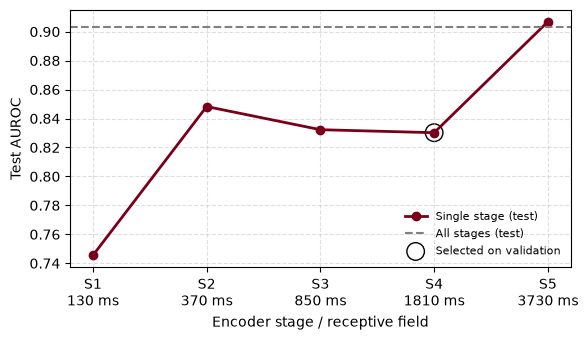

In [11]:
st = res[res.level != "all_stages"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(st)), st.test_auroc, "o-", color="#7a0019", lw=2, label="Single stage (test)")
ax.axhline(res.loc[res.level == "all_stages", "test_auroc"].item(), ls="--", color="grey", label="All stages (test)")
sel = st.selected_on_validation.to_numpy()
ax.scatter(np.arange(len(st))[sel], st.test_auroc[sel], s=160, facecolors="none", edgecolors="k", label="Selected on validation")
ax.set_xticks(range(len(st)))
ax.set_xticklabels([f"S{i+1}\n{rf:.0f} ms" for i, rf in enumerate(st.receptive_field_ms)])
ax.set_xlabel("Encoder stage / receptive field"); ax.set_ylabel("Test AUROC")
ax.grid(True, ls="--", alpha=0.4); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()